<div style="background:#17364e;color:white;padding:26px;border-radius:8px">
<p style="color:#a6d9ed;letter-spacing:2px">CLASSIFICATION · ENSEMBLE MODELS · CHURN ANALYSIS</p>
<h1 style="color:white">Customer Churn Classification</h1>
<p>Random Forest and XGBoost on telecom subscription data</p>
<p>Arafat Rahman</p>
</div>

Identify customers likely to churn using subscription and billing attributes.
Compare two weighted ensemble classifiers with training-only cross-validation,
then evaluate ranking quality and classification errors on an untouched test set.

## 01 · Data and Evaluation Plan

Use the [Telco Customer Churn CSV](https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv)
linked by the [official assignment](https://www.datheon.in/training/catalog/machine-learning-and-data-science-internship).
Each row represents a customer. `Churn=Yes` is the positive class.

The evaluation uses a stratified 80/20 split and five-fold stratified cross-validation on training data.
The model with the highest mean validation ROC-AUC is selected before test evaluation.
The assignment's ROC-AUC target is **greater than 0.80**; actual performance is reported without guarantees.
Classification uses a fixed **0.50 threshold**, with no threshold tuning on the test set.

## 02 · Imports and Reproducibility

Fixed seeds, explicit class labels and shared colours keep the comparison readable and reproducible. Internet access is needed to load the source.

In [1]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
from importlib.metadata import version
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix)
from sklearn.utils.validation import check_is_fitted
from xgboost import XGBClassifier

SEED = 42
THRESHOLD = 0.50
CLASS_NAMES = ['No churn', 'Churn']
MODEL_COLORS = {'Random Forest':'#26748e', 'XGBoost':'#c67d23'}
np.random.seed(SEED)
sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':220, 'axes.titleweight':'bold',
                     'axes.spines.top':False, 'axes.spines.right':False, 'grid.alpha':0.22})
pd.set_option('display.precision',4)
cwd = Path.cwd()
if cwd.name == 'Task_03_Customer_Churn_Classification':
    TASK_DIR = cwd
elif (cwd / 'Task_03_Customer_Churn_Classification').is_dir():
    TASK_DIR = cwd / 'Task_03_Customer_Churn_Classification'
elif cwd == Path('/kaggle/working'):
    TASK_DIR = cwd / 'Task_03_Customer_Churn_Classification'
    TASK_DIR.mkdir(exist_ok=True)
else:
    raise RuntimeError('Run from the project root, Task 3 folder or /kaggle/working.')
RESULTS, FIGURES = TASK_DIR / 'results', TASK_DIR / 'figures'
RESULTS.mkdir(exist_ok=True)
FIGURES.mkdir(exist_ok=True)
def save_figure(fig, filename):
    fig.savefig(FIGURES/filename, bbox_inches='tight', facecolor='white')
display(pd.Series({p:version(p) for p in ['numpy','pandas','scikit-learn','xgboost','matplotlib','seaborn']},name='Version').to_frame())

,Version
numpy,2.5.4
pandas,3.0.6
scikit-learn,1.9.1
xgboost,3.4.1
matplotlib,3.11.2
seaborn,0.13.2


## 03 · Source Loading and Schema Validation

Read the official CSV directly into memory and record its fingerprint. A download failure stops execution; no alternate source is silently substituted.

In [2]:
DATA_URL = 'https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv'
with urlopen(DATA_URL, timeout=60) as response:
    source_bytes = response.read()
source_sha256 = hashlib.sha256(source_bytes).hexdigest()
telco = pd.read_csv(BytesIO(source_bytes))
expected = ['customerID','gender','SeniorCitizen','Partner','Dependents','tenure','PhoneService',
            'MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection',
            'TechSupport','StreamingTV','StreamingMovies','Contract','PaperlessBilling',
            'PaymentMethod','MonthlyCharges','TotalCharges','Churn']
assert telco.shape == (7043,21)
assert telco.columns.tolist() == expected
assert telco['customerID'].notna().all() and telco['customerID'].is_unique
assert set(telco['Churn']) == {'No','Yes'}
assert telco['Churn'].notna().all()
print('Validated shape:',telco.shape)
print('Source SHA-256:',source_sha256)
display(telco.drop(columns='customerID').head())

Validated shape: (7043, 21)
Source SHA-256: 16320c9c1ec72448db59aa0a26a0b95401046bef5d02fd3aeb906448e3055e91


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 04 · Data Quality and TotalCharges

Convert blank `TotalCharges` entries to missing numeric values. Imputation happens inside each training fold. Keep distinct customer records even when their observed profiles match; customer IDs are excluded from model inputs.

In [3]:
raw_total = telco['TotalCharges'].astype(str).str.strip()
telco['TotalCharges'] = pd.to_numeric(raw_total, errors='coerce')
invalid_tokens = raw_total.loc[telco['TotalCharges'].isna() & raw_total.ne('')]
assert invalid_tokens.empty, 'Unexpected nonnumeric TotalCharges values require review.'
quality = pd.DataFrame({'dtype':telco.dtypes.astype(str),'missing':telco.isna().sum(),
                        'unique':telco.nunique()})
display(quality)
missing_total = int(telco['TotalCharges'].isna().sum())
print('Missing TotalCharges:',missing_total)
print('Duplicate full rows:',int(telco.duplicated().sum()))
profile_duplicates = int(telco.drop(columns='customerID').duplicated().sum())
print('Repeated profiles including target, excluding ID:',profile_duplicates)
display(telco.loc[telco['TotalCharges'].isna(),['tenure','MonthlyCharges','TotalCharges','Churn']].head())
NUMERIC = ['tenure','MonthlyCharges','TotalCharges']
assert not np.isinf(telco[NUMERIC].to_numpy()).any()
assert telco[NUMERIC].dropna().ge(0).all().all()

,dtype,missing,unique
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


Missing TotalCharges: 11
Duplicate full rows: 0
Repeated profiles including target, excluding ID: 22


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No


## 05 · Stratified Train-Test Split

Exclude the identifier and target from predictors. Keep the natural churn prevalence in both partitions; weighting changes the training loss, not the test population.

In [4]:
X = telco.drop(columns=['customerID','Churn']).copy()
y = telco['Churn'].map({'No':0,'Yes':1}).astype(int)
# SeniorCitizen is a binary category, not a continuous measurement.
X['SeniorCitizen'] = X['SeniorCitizen'].map({0:'No',1:'Yes'})
CATEGORICAL = [c for c in X.columns if c not in NUMERIC]
assert len(X.columns)==19 and 'customerID' not in X.columns and 'Churn' not in X.columns
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
assert len(X_train)==5634 and len(X_test)==1409
assert set(X_train.index).isdisjoint(X_test.index)
split_counts = pd.DataFrame({'All':y.value_counts(),'Train':y_train.value_counts(),'Test':y_test.value_counts()}).sort_index()
split_counts.index = CLASS_NAMES
display(split_counts)
print(f'Overall churn rate: {y.mean():.2%}; training: {y_train.mean():.2%}; test: {y_test.mean():.2%}')
# Different IDs can still share the same observed predictor profile.
profile_hashes = pd.util.hash_pandas_object(X,index=False)
shared_profiles = len(set(profile_hashes.loc[X_train.index]) & set(profile_hashes.loc[X_test.index]))
print('Identical predictor profiles shared across partitions:',shared_profiles)

,All,Train,Test
No churn,5174,4139,1035
Churn,1869,1495,374


Overall churn rate: 26.54%; training: 26.54%; test: 26.54%
Identical predictor profiles shared across partitions: 12


## 06 · Class Balance and Training Exploration

Explore training rows only. Class imbalance is measured from this dataset rather than assumed to be severe. Contract-level rates describe associations, not reasons customers leave.

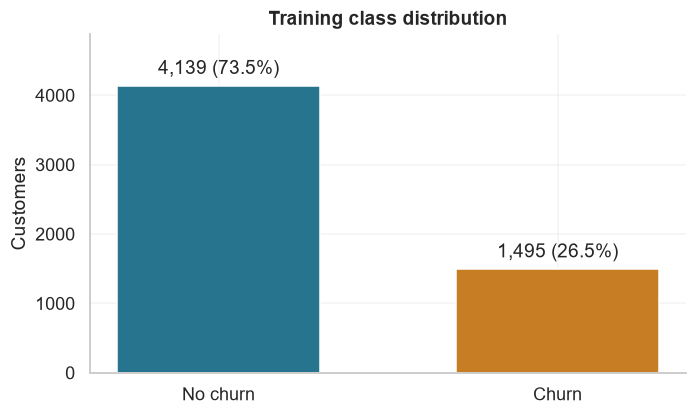

In [5]:
counts = y_train.value_counts().sort_index()
fig,ax = plt.subplots(figsize=(7,4))
bars=ax.bar(CLASS_NAMES,counts.values,color=['#26748e','#c67d23'],width=0.6)
ax.bar_label(bars,labels=[f'{n:,} ({n/len(y_train):.1%})' for n in counts],padding=5)
ax.set(title='Training class distribution',ylabel='Customers',ylim=(0,counts.max()*1.18))
save_figure(fig,'class_distribution.png')
plt.show()

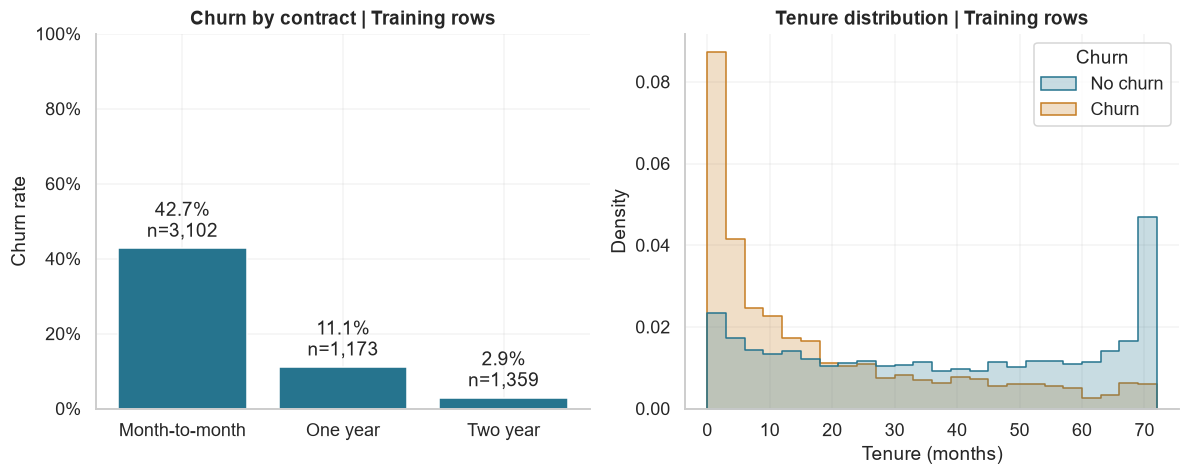

In [6]:
training = X_train.assign(Churn=y_train)
contract = training.groupby('Contract')['Churn'].agg(['mean','size']).reindex(['Month-to-month','One year','Two year'])
fig,axes=plt.subplots(1,2,figsize=(11,4.5))
bars=axes[0].bar(contract.index,contract['mean'],color='#26748e')
axes[0].bar_label(bars,labels=[f'{r:.1%}\nn={n:,}' for r,n in zip(contract['mean'],contract['size'])],padding=4)
axes[0].set(ylim=(0,1),ylabel='Churn rate',title='Churn by contract | Training rows')
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v,p:f'{v:.0%}'))
sns.histplot(data=training,x='tenure',hue='Churn',hue_order=[0,1],bins=24,
             palette=['#26748e','#c67d23'],element='step',stat='density',common_norm=False,ax=axes[1])
axes[1].set(title='Tenure distribution | Training rows',xlabel='Tenure (months)')
legend=axes[1].get_legend()
legend.set_title('Churn')
for label,text in zip(legend.get_texts(),CLASS_NAMES): label.set_text(text)
fig.tight_layout()
save_figure(fig,'training_exploration.png')
plt.show()

## 07 · Preprocessing and Class Weighting

Both models use numeric median imputation and categorical most-frequent imputation followed by one-hot encoding.
All fitted preprocessing stays inside the training folds. Trees do not require feature scaling.

- Random Forest uses `class_weight='balanced'`, computed from the labels in each fit.
- XGBoost uses `scale_pos_weight = negatives / positives`, also computed separately for each fit.
- No SMOTE is applied: class weighting satisfies the requirement and avoids interpolating categorical customer profiles.

In [7]:
def make_pipeline(estimator):
    numeric=Pipeline([('imputer',SimpleImputer(strategy='median'))])
    categorical=Pipeline([('imputer',SimpleImputer(strategy='most_frequent')),
                          ('encoder',OneHotEncoder(handle_unknown='ignore',sparse_output=False))])
    preprocess=ColumnTransformer([('numeric',numeric,NUMERIC),
                                  ('category',categorical,CATEGORICAL)])
    return Pipeline([('preprocess',preprocess),('model',estimator)])

templates = {
    'Random Forest':make_pipeline(RandomForestClassifier(n_estimators=300,max_depth=12,
                         min_samples_leaf=5,max_features=0.7,class_weight='balanced',
                         random_state=SEED,n_jobs=2)),
    'XGBoost':make_pipeline(XGBClassifier(n_estimators=300,max_depth=3,learning_rate=0.05,
                         subsample=0.8,colsample_bytree=0.8,reg_lambda=5,
                         objective='binary:logistic',eval_metric='logloss',
                         tree_method='hist',random_state=SEED,n_jobs=2))
}

def fit_weighted(name, model, features, target):
    if name=='XGBoost':
        negative=int(target.eq(0).sum())
        positive=int(target.eq(1).sum())
        assert positive>0 and negative>0
        model.set_params(model__scale_pos_weight=negative/positive)
    model.fit(features,target)
    return model
print('Preprocessing and class weights are fitted only from the rows supplied to each fit.')

Preprocessing and class weights are fitted only from the rows supplied to each fit.


## 08 · Training-Only Cross-Validation

Use identical five-fold stratified splits for both models. Settings are fixed before test evaluation. Store every fold score and select by mean validation ROC-AUC, not by test accuracy.

In [8]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
folds=list(cv.split(X_train,y_train))
cv_rows=[]
for name,template in templates.items():
    for fold,(fit_indices,valid_indices) in enumerate(folds,start=1):
        fold_X,fold_y=X_train.iloc[fit_indices],y_train.iloc[fit_indices]
        valid_X,valid_y=X_train.iloc[valid_indices],y_train.iloc[valid_indices]
        model=fit_weighted(name,clone(template),fold_X,fold_y)
        scores=model.predict_proba(valid_X)[:,1]
        cv_rows.append({'Model':name,'Fold':fold,'ROC AUC':roc_auc_score(valid_y,scores),
                        'Average Precision':average_precision_score(valid_y,scores),
                        'Training negatives':int(fold_y.eq(0).sum()),
                        'Training positives':int(fold_y.eq(1).sum())})
cv_results=pd.DataFrame(cv_rows)
cv_results.to_csv(RESULTS/'cross_validation.csv',index=False)
cv_summary=cv_results.groupby('Model').agg(CV_ROC_AUC=('ROC AUC','mean'),
                                           CV_ROC_AUC_std=('ROC AUC','std'),
                                           CV_AP=('Average Precision','mean')).reindex(templates)
selected_name=cv_summary['CV_ROC_AUC'].idxmax()
display(cv_summary.round(4))
display(Markdown(f'**Selected before test evaluation: {selected_name}.** Fold standard deviation is descriptive, not a confidence interval.'))

,CV_ROC_AUC,CV_ROC_AUC_std,CV_AP
Model,,,
Random Forest,0.8409,0.0102,0.6528
XGBoost,0.8473,0.0121,0.6687


**Selected before test evaluation: XGBoost.** Fold standard deviation is descriptive, not a confidence interval.

## 09 · Fit Final Models

Refit both complete pipelines on all training rows. The test set is used only in the evaluation sections that follow.

In [9]:
models={name:fit_weighted(name,clone(template),X_train,y_train) for name,template in templates.items()}
for name,model in models.items():
    check_is_fitted(model.named_steps['model'])
    numeric=model.named_steps['preprocess'].named_transformers_['numeric'].named_steps['imputer']
    np.testing.assert_allclose(numeric.statistics_,X_train[NUMERIC].median().to_numpy())
print('Final XGBoost scale_pos_weight:',models['XGBoost'].named_steps['model'].get_params()['scale_pos_weight'])
print('Both models fitted on',len(X_train),'training customers.')

Final XGBoost scale_pos_weight: 2.768561872909699
Both models fitted on 5634 training customers.


## 10 · Held-Out Metrics

ROC-AUC and Average Precision use continuous scores. Precision, recall, F1 and accuracy use the fixed 0.50 threshold. Precision/recall/F1 refer to churn (positive class). Average Precision is a step-weighted PR summary, not trapezoidal PR-AUC.

In [10]:
probabilities={name:model.predict_proba(X_test)[:,1] for name,model in models.items()}
predictions={name:(scores>=THRESHOLD).astype(int) for name,scores in probabilities.items()}
rows=[]
for name,scores in probabilities.items():
    predicted=predictions[name]
    assert np.isfinite(scores).all() and ((scores>=0)&(scores<=1)).all()
    rows.append({'Model':name,'ROC AUC':roc_auc_score(y_test,scores),
        'Average Precision':average_precision_score(y_test,scores),
        'Accuracy':accuracy_score(y_test,predicted),
        'Precision':precision_score(y_test,predicted,zero_division=0),
        'Recall':recall_score(y_test,predicted,zero_division=0),
        'F1':f1_score(y_test,predicted,zero_division=0),
        **cv_summary.loc[name].to_dict()})
comparison=pd.DataFrame(rows).set_index('Model')
comparison.to_csv(RESULTS/'model_comparison.csv')
display(comparison.round(4))
print(f'Always-no-churn accuracy baseline: {y_test.eq(0).mean():.2%}')
print(f'Random-ranking reference: ROC-AUC 0.50; PR prevalence {y_test.mean():.2%}')
saved_predictions=pd.DataFrame({'source_row':X_test.index,'true_churn':y_test.to_numpy()})
for name in models:
    saved_predictions[name+' probability']=probabilities[name]
    saved_predictions[name+' prediction']=predictions[name]
saved_predictions.to_csv(RESULTS/'test_predictions.csv',index=False)

,ROC AUC,Average Precision,Accuracy,Precision,Recall,F1,CV_ROC_AUC,CV_ROC_AUC_std,CV_AP
Model,,,,,,,,,
Random Forest,0.8350,0.6357,0.7608,0.5358,0.7406,0.6218,0.8409,0.0102,0.6528
XGBoost,0.8463,0.6669,0.7509,0.5204,0.7861,0.6262,0.8473,0.0121,0.6687


Always-no-churn accuracy baseline: 73.46%
Random-ranking reference: ROC-AUC 0.50; PR prevalence 26.54%


## 11 · ROC and Precision-Recall Curves

ROC shows the trade-off between true- and false-positive rates. Precision-recall highlights performance on the minority churn class. Neither curve implies calibrated churn probabilities.

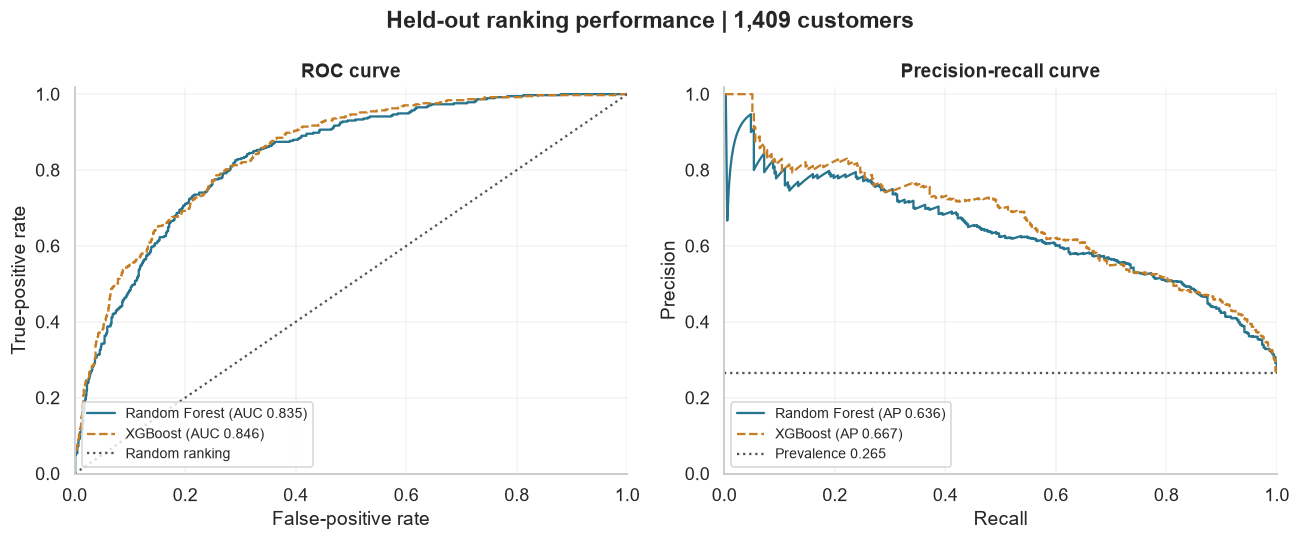

In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,5))
for name,scores in probabilities.items():
    fpr,tpr,_=roc_curve(y_test,scores)
    precision,recall,_=precision_recall_curve(y_test,scores)
    axes[0].plot(fpr,tpr,color=MODEL_COLORS[name],linestyle='-' if name=='Random Forest' else '--',
                 label=f"{name} (AUC {comparison.loc[name,'ROC AUC']:.3f})")
    axes[1].plot(recall,precision,color=MODEL_COLORS[name],linestyle='-' if name=='Random Forest' else '--',
                 label=f"{name} (AP {comparison.loc[name,'Average Precision']:.3f})")
axes[0].plot([0,1],[0,1],':',color='#555555',label='Random ranking')
axes[1].axhline(y_test.mean(),linestyle=':',color='#555555',label=f'Prevalence {y_test.mean():.3f}')
axes[0].set(title='ROC curve',xlabel='False-positive rate',ylabel='True-positive rate',xlim=(0,1),ylim=(0,1.02))
axes[1].set(title='Precision-recall curve',xlabel='Recall',ylabel='Precision',xlim=(0,1),ylim=(0,1.02))
for ax in axes: ax.legend(loc='lower left',fontsize=9)
fig.suptitle('Held-out ranking performance | 1,409 customers',weight='bold')
fig.tight_layout()
save_figure(fig,'roc_precision_recall.png')
plt.show()

## 12 · Classification Reports and Confusion Matrices

False negatives are churners missed by the model; false positives are customers flagged as churners who did not churn in the recorded label. Counts depend on the chosen threshold.

Random Forest
              precision    recall  f1-score   support

    No churn     0.8913    0.7681    0.8251      1035
       Churn     0.5358    0.7406    0.6218       374

    accuracy                         0.7608      1409
   macro avg     0.7135    0.7544    0.7234      1409
weighted avg     0.7969    0.7608    0.7711      1409

XGBoost
              precision    recall  f1-score   support

    No churn     0.9052    0.7382    0.8132      1035
       Churn     0.5204    0.7861    0.6262       374

    accuracy                         0.7509      1409
   macro avg     0.7128    0.7621    0.7197      1409
weighted avg     0.8031    0.7509    0.7636      1409



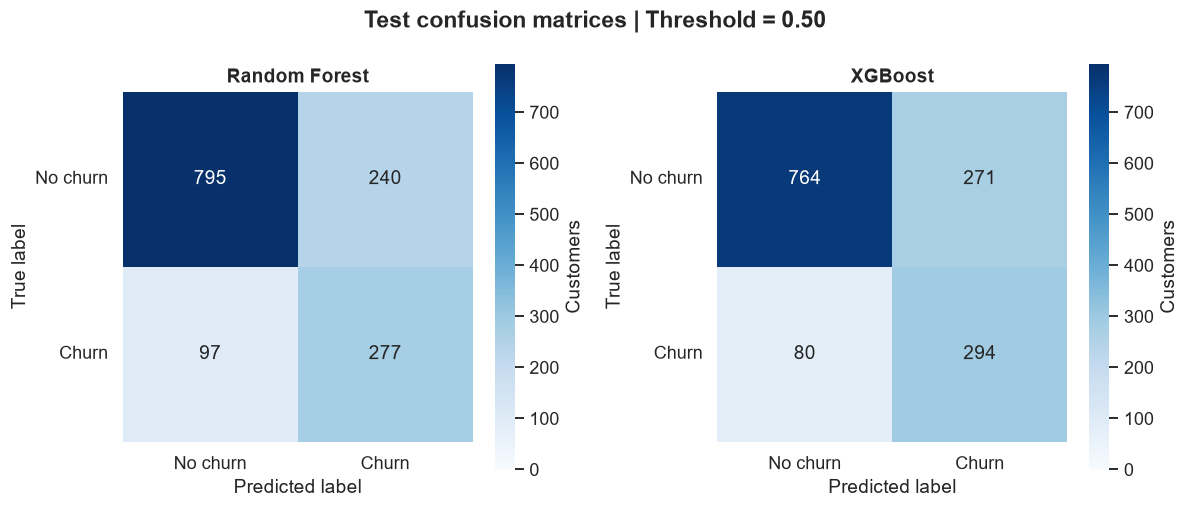

In [12]:
reports=[]
matrices={}
for name,predicted in predictions.items():
    report=classification_report(y_test,predicted,labels=[0,1],target_names=CLASS_NAMES,digits=4,zero_division=0)
    print(name+'\n'+report)
    reports.append(name+'\n'+report)
    matrices[name]=confusion_matrix(y_test,predicted,labels=[0,1])
(RESULTS/'classification_reports.txt').write_text('\n'.join(reports),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(11,4.7))
vmax=max(matrix.max() for matrix in matrices.values())
for ax,(name,matrix) in zip(axes,matrices.items()):
    sns.heatmap(matrix,annot=True,fmt='d',cmap='Blues',vmin=0,vmax=vmax,square=True,
                xticklabels=CLASS_NAMES,yticklabels=CLASS_NAMES,ax=ax,cbar_kws={'label':'Customers'})
    ax.set(title=name,xlabel='Predicted label',ylabel='True label')
    ax.tick_params(axis='y',rotation=0)
fig.suptitle('Test confusion matrices | Threshold = 0.50',weight='bold')
fig.tight_layout()
save_figure(fig,'confusion_matrices.png')
plt.show()

## 13 · Compact Model Comparison

Use a common scale for all metrics. High accuracy alone is insufficient when most customers do not churn.

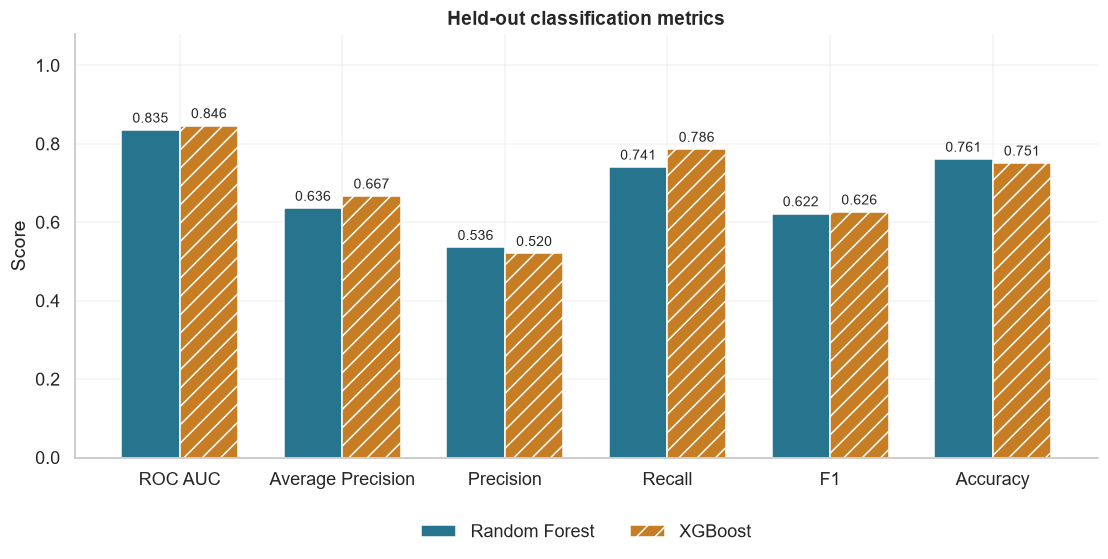

In [13]:
metrics=['ROC AUC','Average Precision','Precision','Recall','F1','Accuracy']
fig,ax=plt.subplots(figsize=(12,5))
positions=np.arange(len(metrics))
for i,name in enumerate(models):
    values=comparison.loc[name,metrics].to_numpy(dtype=float)
    bars=ax.bar(positions+(i-0.5)*0.36,values,width=0.36,color=MODEL_COLORS[name],
                 hatch='' if i==0 else '//',label=name)
    ax.bar_label(bars,labels=[f'{v:.3f}' for v in values],padding=3,fontsize=9)
ax.set_xticks(positions,metrics)
ax.set(ylim=(0,1.08),ylabel='Score',title='Held-out classification metrics')
ax.legend(loc='upper center',bbox_to_anchor=(0.5,-0.12),ncol=2,frameon=False)
save_figure(fig,'model_comparison.png')
plt.show()

## 14 · Top Ten Feature Importances

Rank the encoded features within each fitted model. Random Forest uses normalized impurity reduction; XGBoost uses normalized average gain. These quantities differ, can favour certain predictors and are not causal effects or directly comparable between models.

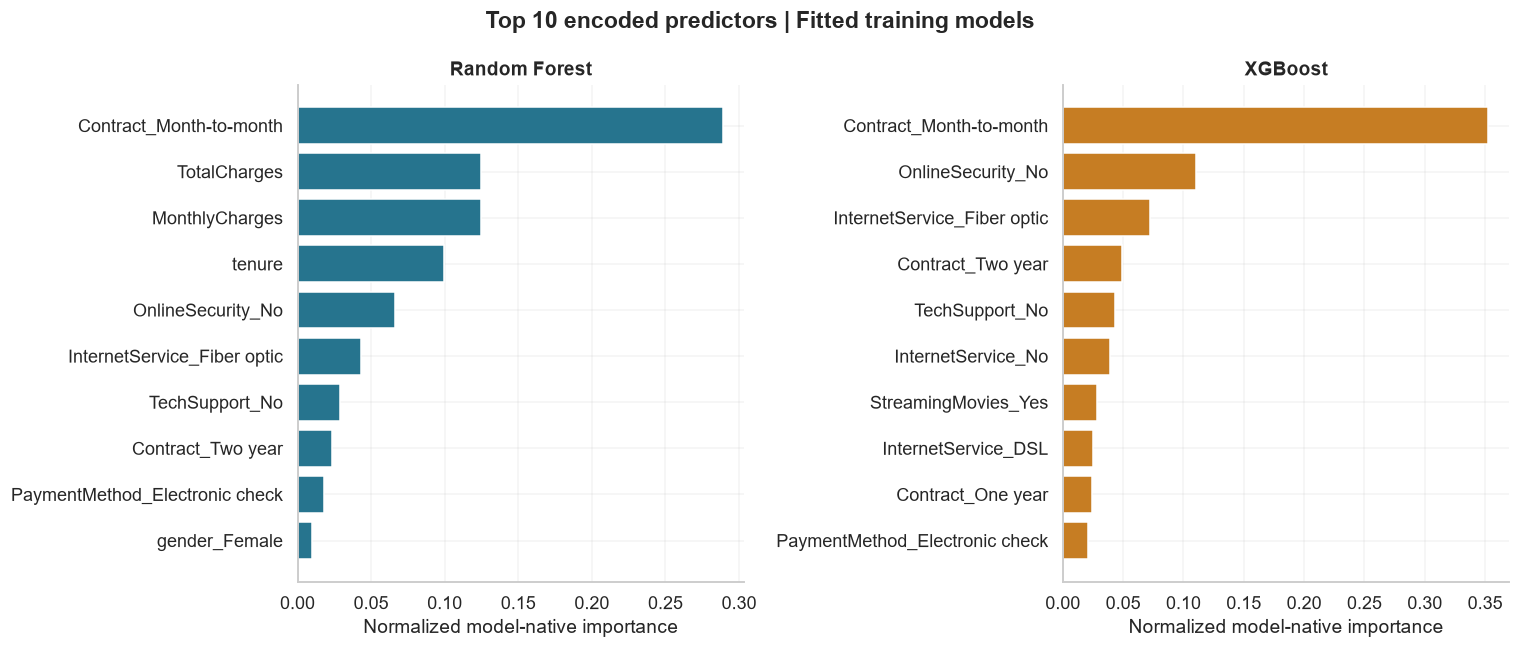

In [14]:
importance_rows=[]
fig,axes=plt.subplots(1,2,figsize=(14,6))
for ax,(name,model) in zip(axes,models.items()):
    names=model.named_steps['preprocess'].get_feature_names_out()
    values=model.named_steps['model'].feature_importances_
    importance=pd.Series(values,index=names).sort_values(ascending=False)
    for feature,value in importance.items():
        importance_rows.append({'Model':name,'Feature':feature,'Importance':float(value)})
    top=importance.head(10).sort_values()
    labels=[label.replace('numeric__','').replace('category__','') for label in top.index]
    ax.barh(labels,top.values,color=MODEL_COLORS[name])
    ax.set(title=name,xlabel='Normalized model-native importance')
fig.suptitle('Top 10 encoded predictors | Fitted training models',weight='bold')
fig.tight_layout()
save_figure(fig,'feature_importances.png')
plt.show()
pd.DataFrame(importance_rows).to_csv(RESULTS/'feature_importances.csv',index=False)

## 15 · Error Analysis

Report false positives and false negatives for both models. Inspect the selected model's most confident incorrect predictions, using source row indices rather than customer IDs. Confidence here is a model score, not a calibrated probability.

In [15]:
error_rows=[]
for name,matrix in matrices.items():
    tn,fp,fn,tp=matrix.ravel()
    error_rows.append({'Model':name,'True negatives':int(tn),'False positives':int(fp),
                       'False negatives':int(fn),'True positives':int(tp),'Errors':int(fp+fn)})
error_counts=pd.DataFrame(error_rows).set_index('Model')
display(error_counts)
error_counts.to_csv(RESULTS/'error_counts.csv')
errors=X_test[['tenure','MonthlyCharges','TotalCharges','Contract','InternetService']].copy()
errors['true_churn']=y_test
errors['predicted_churn']=predictions[selected_name]
errors['churn_score']=probabilities[selected_name]
errors=errors.loc[errors['true_churn'].ne(errors['predicted_churn'])].copy()
errors['error_type']=np.where(errors['true_churn'].eq(1),'False negative','False positive')
errors['confidence_in_wrong_label']=np.where(errors['predicted_churn'].eq(1),errors['churn_score'],1-errors['churn_score'])
errors=errors.sort_values('confidence_in_wrong_label',ascending=False)
errors.index.name='source_row'
errors.to_csv(RESULTS/'misclassified_customers.csv')
display(errors.head(10).round(3))

,True negatives,False positives,False negatives,True positives,Errors
Model,,,,,
Random Forest,795,240,97,277,337
XGBoost,764,271,80,294,351


,tenure,MonthlyCharges,TotalCharges,Contract,InternetService,true_churn,predicted_churn,churn_score,error_type,confidence_in_wrong_label
source_row,,,,,,,,,,
4513,72,92.45,6440.25,Two year,DSL,1,0,0.011,False negative,0.989
4386,55,57.55,3046.40,Two year,DSL,1,0,0.036,False negative,0.964
3790,2,19.30,28.30,One year,No,1,0,0.041,False negative,0.959
4039,7,94.10,701.30,Month-to-month,Fiber optic,0,1,0.942,False positive,0.942
2244,34,64.40,2088.75,One year,DSL,1,0,0.059,False negative,0.941
5086,45,20.40,930.45,One year,No,1,0,0.059,False negative,0.941
3346,2,84.05,186.05,Month-to-month,Fiber optic,0,1,0.940,False positive,0.940
3536,1,79.15,79.15,Month-to-month,Fiber optic,0,1,0.937,False positive,0.937
5905,1,85.00,85.00,Month-to-month,Fiber optic,0,1,0.936,False positive,0.936


## 16 · Findings and Limitations

The summary is computed from actual held-out predictions. No features, weights or thresholds are changed after reviewing these results.

In [16]:
selected=comparison.loc[selected_name]
test_leader=comparison['ROC AUC'].idxmax()
display(Markdown(
    f"Training CV selected **{selected_name}** (mean ROC-AUC **{selected['CV_ROC_AUC']:.4f}**). "
    f"On the test set, it achieved ROC-AUC **{selected['ROC AUC']:.4f}**, "
    f"Average Precision **{selected['Average Precision']:.4f}**, churn recall **{selected['Recall']:.2%}** "
    f"and F1 **{selected['F1']:.4f}** at threshold 0.50. "
    f"The highest observed test ROC-AUC belongs to **{test_leader}**; selection remains based on training CV."
))
for name,row in comparison.iterrows():
    print(f"{name}: ROC-AUC > 0.80 target {'met' if row['ROC AUC']>0.80 else 'not met'} ({row['ROC AUC']:.4f}).")
summary={'selected_by_cv':selected_name,'highest_test_auc':test_leader,
         'train_rows':len(X_train),'test_rows':len(X_test),'churn_rate':float(y.mean()),
         'missing_total_charges':missing_total,'shared_predictor_profiles':shared_profiles,
         'source_sha256':source_sha256,'threshold':THRESHOLD,
         'auc_target_met':{name:bool(row['ROC AUC']>0.80) for name,row in comparison.iterrows()}}
(RESULTS/'run_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')

Training CV selected **XGBoost** (mean ROC-AUC **0.8473**). On the test set, it achieved ROC-AUC **0.8463**, Average Precision **0.6669**, churn recall **78.61%** and F1 **0.6262** at threshold 0.50. The highest observed test ROC-AUC belongs to **XGBoost**; selection remains based on training CV.

Random Forest: ROC-AUC > 0.80 target met (0.8350).
XGBoost: ROC-AUC > 0.80 target met (0.8463).


392

- The benchmark is a static snapshot. A random split does not establish performance on future customers or changes in pricing and services.
- Distinct customers can share observed profiles; the cross-partition count above makes this limitation explicit. Customer IDs are excluded, but similar profiles can still make a random split optimistic.
- Weighting can increase churn detection at the cost of more false positives. A business threshold would require validation data and explicit intervention costs.
- Weighted model scores are not calibrated probabilities. No claim is made that a score of 0.80 means an 80% real-world churn probability.
- Model-native importance identifies predictive patterns, not causal churn drivers. Protected or demographic attributes should not be treated as causal explanations.
- CV fold variability and a single held-out sample do not establish universal superiority or uncertainty intervals.
- The source URL follows an upstream branch; its fingerprint records the exact dataset used. Internet is required to rerun.

## 17 · Verification

Recalculate classification metrics from confusion-matrix counts and verify ranking metrics from saved predictions. Confirm every required artifact exists.

In [17]:
saved=pd.read_csv(RESULTS/'test_predictions.csv')
for name,matrix in matrices.items():
    tn,fp,fn,tp=matrix.ravel()
    manual=[(tp+tn)/matrix.sum(),tp/(tp+fp) if tp+fp else 0,
            tp/(tp+fn) if tp+fn else 0,2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0]
    np.testing.assert_allclose(comparison.loc[name,['Accuracy','Precision','Recall','F1']].to_numpy(dtype=float),manual)
    scores=saved[name+' probability'].to_numpy()
    np.testing.assert_array_equal(saved[name+' prediction'],(scores>=THRESHOLD).astype(int))
    np.testing.assert_allclose(roc_auc_score(saved['true_churn'],scores),comparison.loc[name,'ROC AUC'])
    np.testing.assert_allclose(average_precision_score(saved['true_churn'],scores),comparison.loc[name,'Average Precision'])
    assert matrix.sum()==len(X_test)
    assert error_counts.loc[name,'Errors']==int((saved[name+' prediction']!=saved['true_churn']).sum())
assert selected_name==cv_summary['CV_ROC_AUC'].idxmax()
expected_ratio=float(y_train.eq(0).sum()/y_train.eq(1).sum())
np.testing.assert_allclose(models['XGBoost'].named_steps['model'].get_params()['scale_pos_weight'],expected_ratio)
for filename in ['class_distribution.png','training_exploration.png','roc_precision_recall.png',
                 'confusion_matrices.png','model_comparison.png','feature_importances.png']:
    assert (FIGURES/filename).stat().st_size>1000
for filename in ['cross_validation.csv','model_comparison.csv','test_predictions.csv','classification_reports.txt',
                 'feature_importances.csv','error_counts.csv','misclassified_customers.csv','run_summary.json']:
    assert (RESULTS/filename).stat().st_size>0
print('Verified: source, split, preprocessing, weights, fitted models, metrics, 6 figures and 8 results files.')

Verified: source, split, preprocessing, weights, fitted models, metrics, 6 figures and 8 results files.
